# BMI Estimation using Machine Learning

**Minor project** - Machine Learning using Python, Naviotech Solutions Pvt. Ltd., Indore
**Author:** Rahul Bhardwaj, B.Sc. Industrial Chemistry, Deshbandhu College, University of Delhi

## Problem statement
Estimate a person's **BMI Index** from **Gender**, **Height (cm)** and **Weight (kg)**.

| Index | Class |
|------:|-------|
| 0 | Extremely Weak |
| 1 | Weak |
| 2 | Normal |
| 3 | Overweight |
| 4 | Obesity |
| 5 | Extreme Obesity |

## Steps
1. Read the data and explore it with plots
2. Encode Gender and split into train / test
3. Model 1 - Linear Regression
4. Models 2 and 3 - Logistic Regression and KNN
5. Compare the models (test accuracy and 5-fold cross validation)
6. Predict the Index for new people

## 0. Import libraries and set up paths
Run this notebook from the project folder (the one that contains the `data` folder).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler

DATA_FILE = Path("data") / "bmi.xlsx"
OUT_DIR = Path("outputs")          # graphs are saved here
OUT_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
CLASS_NAMES = {
    0: "Extremely Weak",
    1: "Weak",
    2: "Normal",
    3: "Overweight",
    4: "Obesity",
    5: "Extreme Obesity",
}


def show_and_save(filename):
    """Save the current graph into the outputs folder and also show it in the notebook."""
    plt.tight_layout()
    plt.savefig(OUT_DIR / filename, dpi=150)
    plt.show()

## 1. Read the data

In [2]:
df = pd.read_excel(DATA_FILE)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (500, 4)


,Gender,Height,Weight,Index
0,Male,174,96,4
1,Male,189,87,2
2,Female,185,110,4
3,Female,195,104,3
4,Male,149,61,3


In [3]:
# Any missing values?
df.isnull().sum()

Gender    0
Height    0
Weight    0
Index     0
dtype: int64

In [4]:
df.describe().round(2)

,Height,Weight,Index
count,500.00,500.00,500.00
mean,169.94,106.00,3.75
std,16.38,32.38,1.36
min,140.00,50.00,0.00
25%,156.00,80.00,3.00
50%,170.50,106.00,4.00
75%,184.00,136.00,5.00
max,199.00,160.00,5.00


## 2. Data visualisation

### 2a. Bar plot - how many people in each BMI class

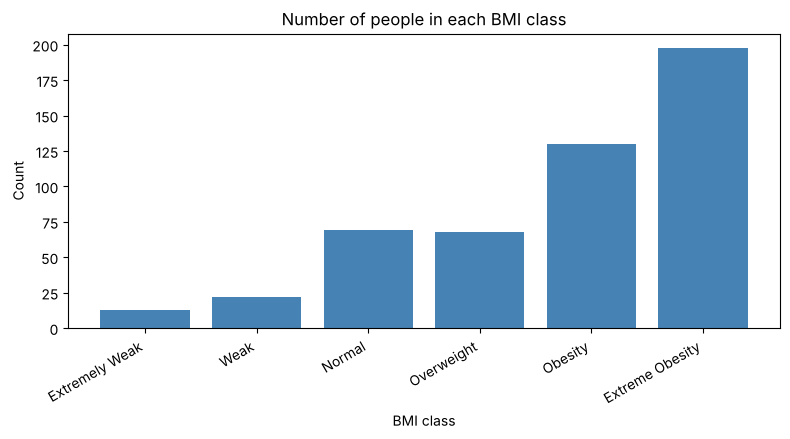

In [5]:
counts = df["Index"].value_counts().sort_index()
plt.figure(figsize=(8, 4.5))
plt.bar([CLASS_NAMES[i] for i in counts.index], counts.values, color="steelblue")
plt.title("Number of people in each BMI class")
plt.xlabel("BMI class")
plt.ylabel("Count")
plt.xticks(rotation=30, ha="right")
show_and_save("01_class_distribution_bar.png")

Most people are in class 5 (Extreme Obesity) and very few are in class 0 and 1, so the data is **imbalanced**.

### 2b. Pie plot - gender share

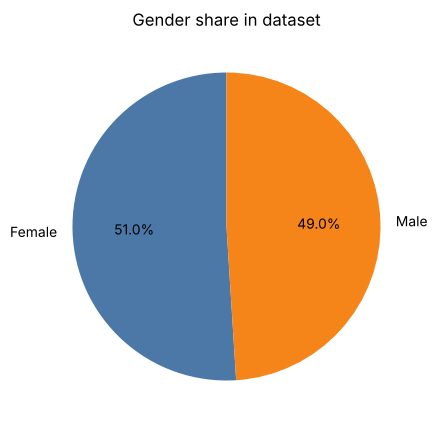

In [6]:
gender_counts = df["Gender"].value_counts()
plt.figure(figsize=(4.5, 4.5))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct="%1.1f%%",
        colors=["#4c78a8", "#f58518"], startangle=90)
plt.title("Gender share in dataset")
show_and_save("02_gender_pie.png")

### 2c. Box plots - weight and height for every BMI class

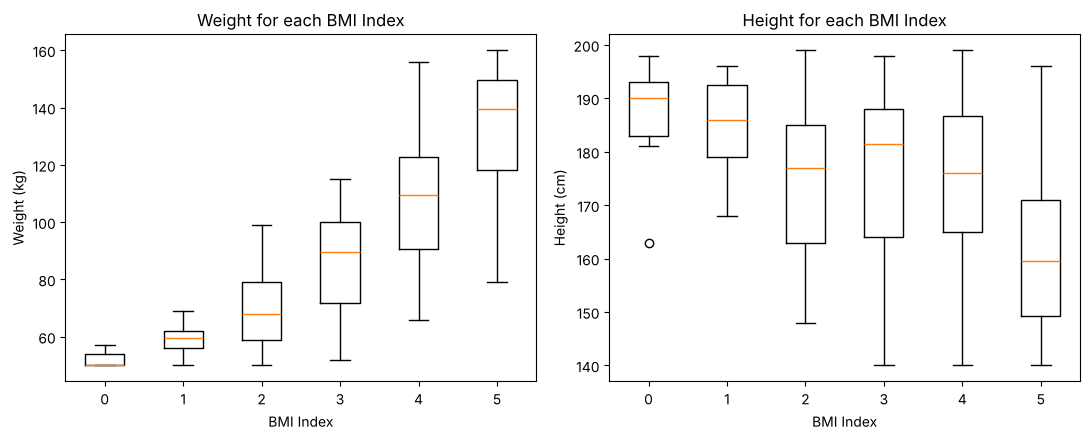

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col in zip(axes, ["Weight", "Height"]):
    data = [df.loc[df["Index"] == i, col] for i in sorted(CLASS_NAMES)]
    ax.boxplot(data, tick_labels=[str(i) for i in sorted(CLASS_NAMES)])
    ax.set_title(f"{col} for each BMI Index")
    ax.set_xlabel("BMI Index")
    ax.set_ylabel(col + (" (kg)" if col == "Weight" else " (cm)"))
show_and_save("03_boxplots_weight_height.png")

Weight rises clearly with the Index. Height shows no clear pattern on its own.

### 2d. Scatter plot - height vs weight, coloured by BMI class

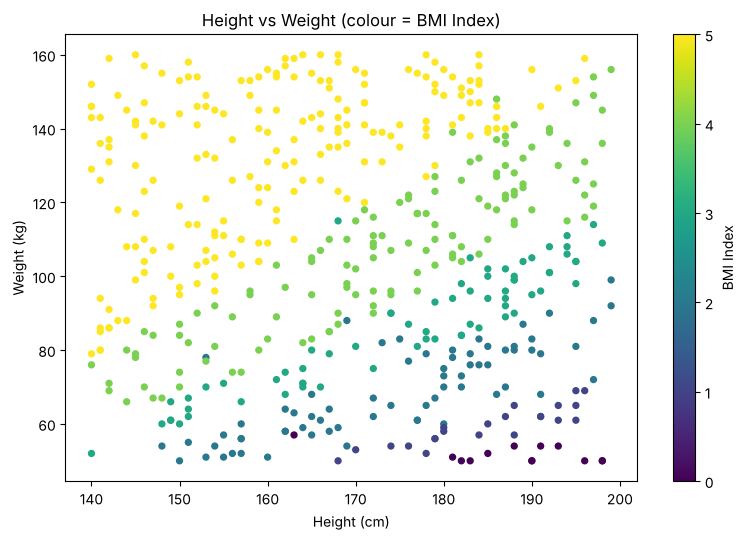

In [8]:
plt.figure(figsize=(8, 5.5))
scatter = plt.scatter(df["Height"], df["Weight"], c=df["Index"], cmap="viridis", s=18)
plt.colorbar(scatter, label="BMI Index")
plt.title("Height vs Weight (colour = BMI Index)")
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
show_and_save("04_height_weight_scatter.png")

## 3. Pre-processing and train / test split
Gender is text, so we convert it into numbers first (Female = 0, Male = 1).
Then we keep 70 % of the data for training and 30 % for testing. `stratify=y` keeps the same class mix in both parts, which matters because some classes are small.

In [9]:
le = LabelEncoder()
df["Gender"] = le.fit_transform(df["Gender"])
print("Gender encoding:", ", ".join(f"{c} = {i}" for i, c in enumerate(le.classes_)))

X = df[["Gender", "Height", "Weight"]]   # inputs
y = df["Index"]                          # output

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, shuffle=True, stratify=y
)
print("Training rows:", len(X_train), "  Testing rows:", len(X_test))

Gender encoding: Female = 0, Male = 1
Training rows: 350   Testing rows: 150


## 4. Model 1 - Linear Regression
Linear regression treats the Index as a number and draws the best straight-line relationship:
`Index = b0 + b1*Gender + b2*Height + b3*Weight`

In [10]:
lin = LinearRegression()
lin.fit(X_train, y_train)

print("Regression equation:")
print(
    f"  Index = {lin.intercept_:.3f} "
    f"+ ({lin.coef_[0]:.3f} x Gender) "
    f"+ ({lin.coef_[1]:.3f} x Height) "
    f"+ ({lin.coef_[2]:.3f} x Weight)"
)

Regression equation:
  Index = 6.035 + (0.060 x Gender) + (-0.035 x Height) + (0.034 x Weight)


Weight has a positive coefficient (heavier -> higher Index). Height has a negative coefficient (for the same weight, a taller person has a lower Index). Gender has a very small effect.

In [11]:
y_pred_lin = lin.predict(X_test)

mse = mean_squared_error(y_test, y_pred_lin)
print(f"MAE  : {mean_absolute_error(y_test, y_pred_lin):.3f}")
print(f"MSE  : {mse:.3f}")
print(f"RMSE : {np.sqrt(mse):.3f}")
print(f"R2   : {r2_score(y_test, y_pred_lin):.3f}")

# Regression gives decimals such as 3.4. Round to the nearest class to compare with the true Index.
y_pred_lin_class = np.clip(np.rint(y_pred_lin), 0, 5).astype(int)
acc_lin = accuracy_score(y_test, y_pred_lin_class)
print(f"Accuracy after rounding to the nearest class: {acc_lin:.3f}")

MAE  : 0.447
MSE  : 0.318
RMSE : 0.564
R2   : 0.829
Accuracy after rounding to the nearest class: 0.693


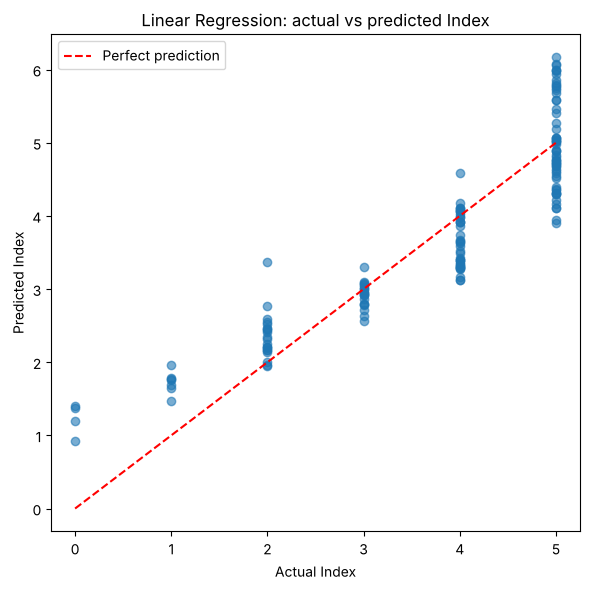

In [12]:
# Actual vs predicted: a perfect model would put every dot on the red line
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_lin, alpha=0.6)
plt.plot([0, 5], [0, 5], "r--", label="Perfect prediction")
plt.title("Linear Regression: actual vs predicted Index")
plt.xlabel("Actual Index")
plt.ylabel("Predicted Index")
plt.legend()
show_and_save("05_linear_actual_vs_predicted.png")

The regression line for each input is drawn while the other inputs are held at their average value.

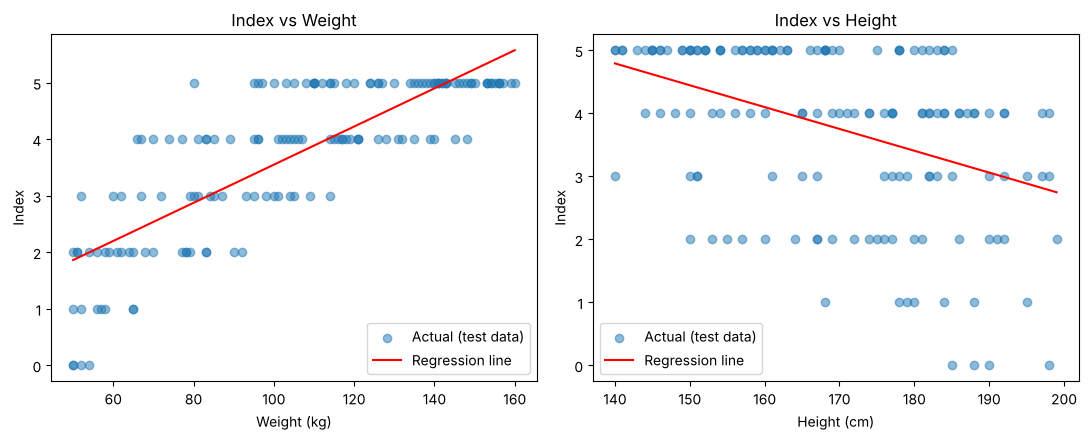

In [13]:
mean_gender, mean_height, mean_weight = X["Gender"].mean(), X["Height"].mean(), X["Weight"].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

w_range = np.linspace(X["Weight"].min(), X["Weight"].max(), 100)
w_line = lin.intercept_ + lin.coef_[0] * mean_gender + lin.coef_[1] * mean_height + lin.coef_[2] * w_range
axes[0].scatter(X_test["Weight"], y_test, alpha=0.5, label="Actual (test data)")
axes[0].plot(w_range, w_line, "r", label="Regression line")
axes[0].set(title="Index vs Weight", xlabel="Weight (kg)", ylabel="Index")
axes[0].legend()

h_range = np.linspace(X["Height"].min(), X["Height"].max(), 100)
h_line = lin.intercept_ + lin.coef_[0] * mean_gender + lin.coef_[1] * h_range + lin.coef_[2] * mean_weight
axes[1].scatter(X_test["Height"], y_test, alpha=0.5, label="Actual (test data)")
axes[1].plot(h_range, h_line, "r", label="Regression line")
axes[1].set(title="Index vs Height", xlabel="Height (cm)", ylabel="Index")
axes[1].legend()
show_and_save("06_linear_index_vs_weight_height.png")

The dots sit in horizontal bands (0 to 5) because the Index is really a **category**, and a straight line cannot follow that well. Classification models should fit better.

## 5. Models 2 and 3 - Logistic Regression and KNN
These models predict the class directly. We scale Height and Weight with `StandardScaler` first. This matters for KNN, which works on distances, and helps Logistic Regression converge.

We also use **5-fold cross validation**: the data is split into 5 parts, and each part is used once for testing. This gives a more reliable accuracy than a single split.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []     # (model name, test accuracy, mean CV accuracy, CV std)


def evaluate(name, model, cm_filename):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    test_acc = accuracy_score(y_test, y_pred)
    cv_scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    results.append((name, test_acc, cv_scores.mean(), cv_scores.std()))

    print(f"Test accuracy      : {test_acc:.3f}")
    print(f"5-fold CV accuracy : {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")
    print("\nPrecision / recall / f1 for every class:")
    print(classification_report(
        y_test, y_pred, target_names=[CLASS_NAMES[i] for i in sorted(CLASS_NAMES)], zero_division=0
    ))
    print("Confusion matrix (rows = actual, columns = predicted):")
    print(confusion_matrix(y_test, y_pred))

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion matrix - {name}")
    show_and_save(cm_filename)
    return model

### 5a. Logistic Regression

Test accuracy      : 0.927
5-fold CV accuracy : 0.928 (+/- 0.021)

Precision / recall / f1 for every class:
                 precision    recall  f1-score   support

 Extremely Weak       1.00      0.25      0.40         4
           Weak       0.62      0.71      0.67         7
         Normal       0.90      0.90      0.90        21
     Overweight       0.95      0.95      0.95        20
        Obesity       0.90      0.97      0.94        39
Extreme Obesity       0.98      0.97      0.97        59

       accuracy                           0.93       150
      macro avg       0.89      0.79      0.81       150
   weighted avg       0.93      0.93      0.92       150

Confusion matrix (rows = actual, columns = predicted):
[[ 1  3  0  0  0  0]
 [ 0  5  2  0  0  0]
 [ 0  0 19  1  1  0]
 [ 0  0  0 19  1  0]
 [ 0  0  0  0 38  1]
 [ 0  0  0  0  2 57]]


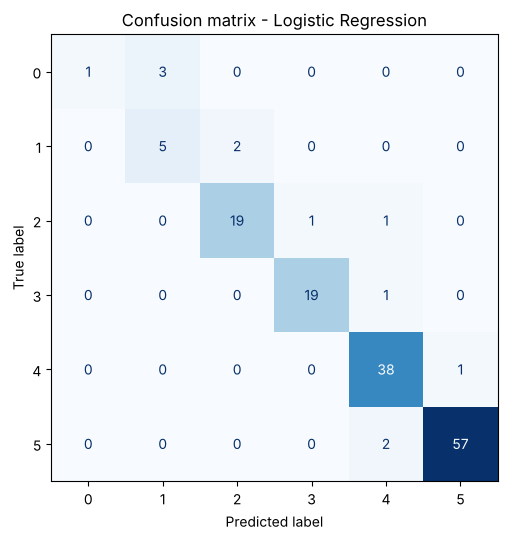

In [15]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(C=10, max_iter=5000))
logreg = evaluate("Logistic Regression", logreg, "07_confusion_logistic.png")

### 5b. K-Nearest Neighbour (k = 5)

Test accuracy      : 0.853
5-fold CV accuracy : 0.866 (+/- 0.041)

Precision / recall / f1 for every class:
                 precision    recall  f1-score   support

 Extremely Weak       0.33      0.25      0.29         4
           Weak       0.43      0.43      0.43         7
         Normal       0.80      0.76      0.78        21
     Overweight       0.80      0.80      0.80        20
        Obesity       0.86      0.92      0.89        39
Extreme Obesity       0.97      0.95      0.96        59

       accuracy                           0.85       150
      macro avg       0.70      0.69      0.69       150
   weighted avg       0.85      0.85      0.85       150

Confusion matrix (rows = actual, columns = predicted):
[[ 1  3  0  0  0  0]
 [ 2  3  2  0  0  0]
 [ 0  1 16  3  1  0]
 [ 0  0  2 16  2  0]
 [ 0  0  0  1 36  2]
 [ 0  0  0  0  3 56]]


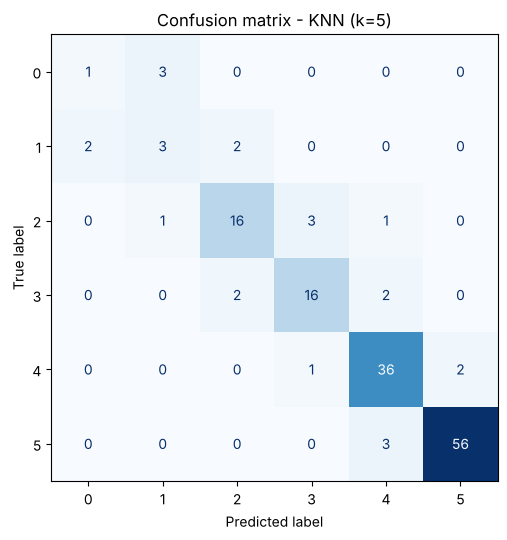

In [16]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn = evaluate("KNN (k=5)", knn, "08_confusion_knn.png")

## 6. Compare the models

In [17]:
# Linear regression (rounded to classes) also goes into the table, using the same 5 folds
cv_lin = []
for train_idx, test_idx in cv.split(X, y):
    m = LinearRegression().fit(X.iloc[train_idx], y.iloc[train_idx])
    pred = np.clip(np.rint(m.predict(X.iloc[test_idx])), 0, 5)
    cv_lin.append(accuracy_score(y.iloc[test_idx], pred))
results.insert(0, ("Linear Regression (rounded)", acc_lin, np.mean(cv_lin), np.std(cv_lin)))

comparison = pd.DataFrame(results, columns=["Model", "Test accuracy", "CV accuracy (mean)", "CV std"])
comparison.round(3)

,Model,Test accuracy,CV accuracy (mean),CV std
0,Linear Regression (rounded),0.693,0.704,0.034
1,Logistic Regression,0.927,0.928,0.021
2,KNN (k=5),0.853,0.866,0.041


Best model by cross-validation: Logistic Regression


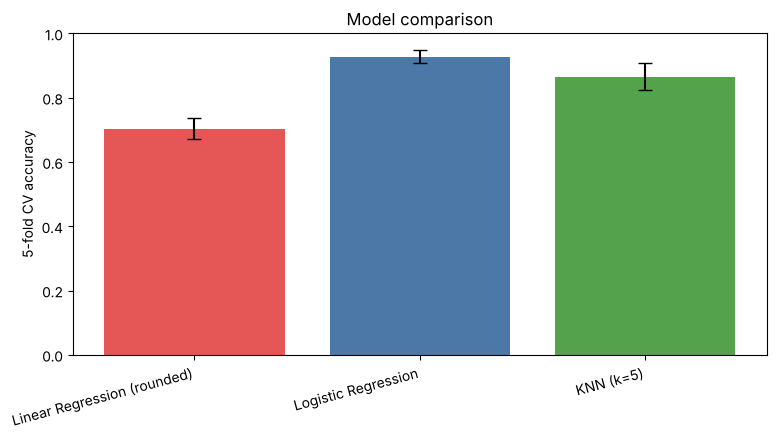

In [18]:
plt.figure(figsize=(8, 4.5))
plt.bar(comparison["Model"], comparison["CV accuracy (mean)"], yerr=comparison["CV std"],
        capsize=5, color=["#e45756", "#4c78a8", "#54a24b"])
plt.ylim(0, 1)
plt.ylabel("5-fold CV accuracy")
plt.title("Model comparison")
plt.xticks(rotation=15, ha="right")
show_and_save("09_model_comparison.png")

best_name = comparison.sort_values("CV accuracy (mean)", ascending=False).iloc[0]["Model"]
print("Best model by cross-validation:", best_name)

**Logistic Regression is the best model.** Linear regression is the weakest because the Index is a category, not a smooth number. The small classes (0 and 1) are the hardest for every model because there are very few examples of them.

## 7. Predict the Index for new people
Change the numbers in the table below to try your own values.

In [19]:
new_people = pd.DataFrame({
    "Gender": ["Male", "Female", "Male", "Female"],
    "Height": [175, 160, 165, 180],     # cm
    "Weight": [70, 90, 140, 50],        # kg
})

encoded = new_people.copy()
encoded["Gender"] = le.transform(new_people["Gender"])   # Female = 0, Male = 1

new_people["Predicted Index"] = logreg.predict(encoded)
new_people["Predicted class"] = new_people["Predicted Index"].map(CLASS_NAMES)
new_people

,Gender,Height,Weight,Predicted Index,Predicted class
0,Male,175,70,2,Normal
1,Female,160,90,4,Obesity
2,Male,165,140,5,Extreme Obesity
3,Female,180,50,0,Extremely Weak


## 8. Conclusion
- Weight is the strongest input; height lowers the Index for the same weight; gender has almost no effect.
- Logistic Regression predicts the BMI class most accurately (about 93 % on test data and in 5-fold cross validation), followed by KNN (about 86 %) and Linear Regression (about 70 %).
- **Limitations:** the dataset is small (500 rows) and imbalanced, and classes 2 and 3 overlap in BMI.
- **Future work:** add BMI (`weight / (height/100)**2`) as a feature, tune `k` for KNN, and try Decision Trees or Random Forest.